# Mobile Game A/B Test: Should Cookie Cats move its first gate from level 30 to level 40?

**Context:** Cookie Cats is a mobile puzzle game. As players progress, they reach *gates* where they must either wait or make an in-app purchase to continue. The team tested moving the first gate from **level 30 to level 40**.

**Question:** Does moving the gate change how many players come back after 1 day and after 7 days?

**Data:** 90,189 players who installed the game during the test, randomly assigned to:
- `gate_30` (control: the current version)
- `gate_40` (treatment: the new version)

| Column | Meaning |
|---|---|
| `userid` | Unique player id |
| `version` | Which group the player was in |
| `sum_gamerounds` | Game rounds played in the first 14 days after install |
| `retention_1` | Did the player come back 1 day after installing? |
| `retention_7` | Did the player come back 7 days after installing? |

**Plan**
1. Check data quality and whether the groups were split fairly
2. Look at engagement (game rounds) and remove clear outliers
3. Compare 1-day and 7-day retention between groups
4. Test whether the differences are real or just random noise (z-test, chi-square, bootstrap)
5. Turn the result into a business recommendation

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Works both from the repo (notebooks/ folder) and with all files in one folder
DATA = Path("../data") if Path("../data").exists() else Path(".")
IMG = Path("../images") if Path("../images").exists() else Path(".")
OUT = Path("../outputs") if Path("../outputs").exists() else Path(".")

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b8b7b1"
MUTED = "#52514e"
COLORS = {"gate_30": BLUE, "gate_40": ORANGE}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True,
})
np.random.seed(42)   # so the bootstrap gives the same numbers every run

## 1. Load and check the data

In [2]:
df = pd.read_csv(DATA / "cookie_cats.csv")
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate user ids:", df["userid"].duplicated().sum())
df.head()

Shape: (90189, 5)
Missing values: 0
Duplicate user ids: 0


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [3]:
group_sizes = df["version"].value_counts().sort_index()
print(group_sizes)
print((group_sizes / len(df) * 100).round(2).astype(str) + " %")

version
gate_30    44700
gate_40    45489
Name: count, dtype: int64
version
gate_30    49.56 %
gate_40    50.44 %
Name: count, dtype: str


### Sample Ratio Mismatch (SRM) check

In a fair 50/50 test, both groups should be about the same size. A **chi-square goodness-of-fit test** tells us whether the gap we see could happen by chance.

In [4]:
expected = [len(df) / 2, len(df) / 2]
srm = stats.chisquare(group_sizes.values, f_exp=expected)
print(f"Chi-square = {srm.statistic:.2f}, p-value = {srm.pvalue:.4f}")

Chi-square = 6.90, p-value = 0.0086


The p-value is below 0.05, so the split is **not exactly 50/50** (49.6% vs 50.4%). The gap is small (789 players out of 90K), and we compare **rates** (% retained), not raw counts, so it doesn't affect the comparison by itself.

In a real company I would still report this to the engineering team. An SRM can mean the assignment system has a bug, for example some users failing to log for one version. For this analysis I continue, but I note it as a limitation.

## 2. Engagement: game rounds played

In [5]:
df["sum_gamerounds"].describe()

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

In [6]:
print("Top 5 players by rounds played:")
print(df.nlargest(5, "sum_gamerounds")[["userid", "version", "sum_gamerounds"]].to_string(index=False))
print(f"\nPlayers who installed but never played a round: {(df['sum_gamerounds'] == 0).sum():,}")

Top 5 players by rounds played:
 userid version  sum_gamerounds
6390605 gate_30           49854
 871500 gate_30            2961
3271615 gate_40            2640
4832608 gate_30            2438
5346171 gate_40            2294

Players who installed but never played a round: 3,994


One player has **49,854 rounds in 14 days**. That is about 3,500 rounds a day, which is not realistic for a human; it's more likely a bot or a logging error. The next highest is 2,961, so this single row is far away from everyone else. I remove only this one player.

Players with 0 rounds stay in the data. They installed the game and left, which is exactly the behaviour retention is supposed to measure.

In [7]:
df = df[df["sum_gamerounds"] < 49854].copy()
print("Players after removing the outlier:", f"{len(df):,}")

Players after removing the outlier: 90,188


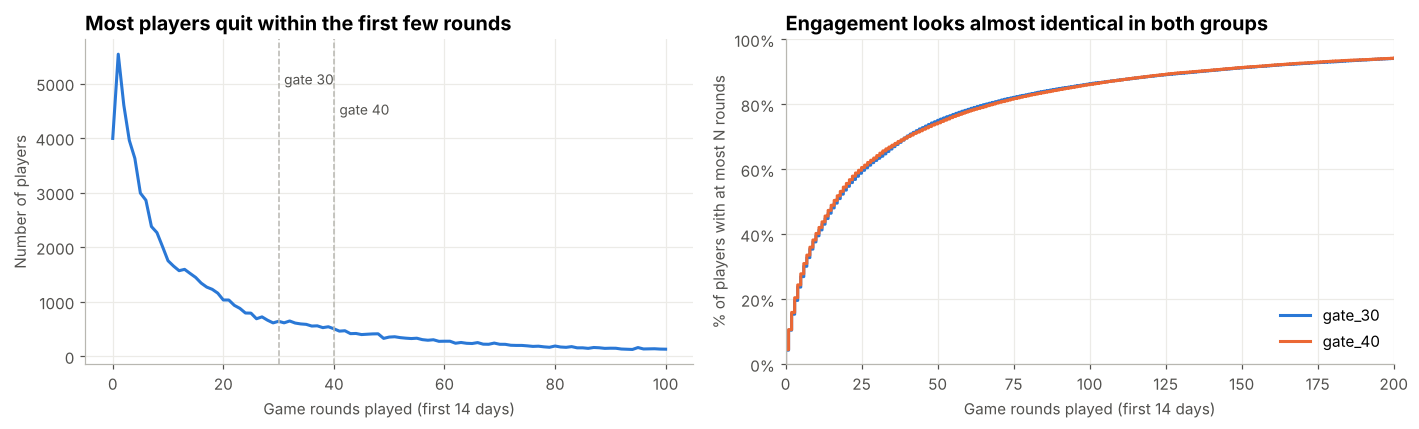

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: how many players stopped after N rounds (first 100 rounds)
rounds = df.groupby("sum_gamerounds")["userid"].count()
axes[0].plot(rounds.loc[:100].index, rounds.loc[:100].values, color=BLUE, lw=2)
axes[0].axvline(30, color=GREY, ls="--", lw=1); axes[0].axvline(40, color=GREY, ls="--", lw=1)
axes[0].text(31, rounds.max() * 0.9, "gate 30", color=MUTED, fontsize=9)
axes[0].text(41, rounds.max() * 0.8, "gate 40", color=MUTED, fontsize=9)
axes[0].set_title("Most players quit within the first few rounds")
axes[0].set_xlabel("Game rounds played (first 14 days)"); axes[0].set_ylabel("Number of players")

# Right: cumulative share of players by rounds played, per group
for v, c in COLORS.items():
    sns.ecdfplot(df.loc[df["version"] == v, "sum_gamerounds"], color=c, lw=2, label=v, ax=axes[1])
axes[1].set_xlim(0, 200)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title("Engagement looks almost identical in both groups")
axes[1].set_xlabel("Game rounds played (first 14 days)"); axes[1].set_ylabel("% of players with at most N rounds")
axes[1].legend(frameon=False, loc="lower right")

plt.tight_layout(); plt.savefig(IMG / "01_gamerounds_distribution.png"); plt.show()

In [9]:
print(df.groupby("version")["sum_gamerounds"].agg(["count", "mean", "median"]).round(2))

         count   mean  median
version                      
gate_30  44699  51.34    17.0
gate_40  45489  51.30    16.0


Game rounds are heavily skewed (a few players play a lot, most play little), so the data is **not normal**. A t-test assumes normal data, so I use the **Mann-Whitney U test**, which compares the two groups without that assumption.

In [10]:
mw = stats.mannwhitneyu(df.loc[df["version"] == "gate_30", "sum_gamerounds"],
                        df.loc[df["version"] == "gate_40", "sum_gamerounds"],
                        alternative="two-sided")
print(f"Mann-Whitney U p-value = {mw.pvalue:.4f}")

Mann-Whitney U p-value = 0.0509


p is just above 0.05 (borderline), so we **cannot say** the groups play a different number of rounds. The medians are almost the same (17 vs 16). The gate change mainly matters for whether players **come back**, which is the next part.

## 3. Retention by group

**Hypotheses** (same for 1-day and 7-day retention):
- **H0 (null):** retention is the same in both groups. Any difference is random noise.
- **H1 (alternative):** retention is different.
- Significance level **α = 0.05**: if p < 0.05, we reject H0 and say the difference is real.

In [11]:
summary = df.groupby("version").agg(
    players=("userid", "count"),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean"),
)
summary[["retention_1", "retention_7"]] *= 100
summary.round(2)

,players,retention_1,retention_7
version,,,
gate_30,44699,44.82,19.02
gate_40,45489,44.23,18.20


### Two-proportion z-test

Retention is a yes/no outcome, so each group's retention is a **proportion**. The z-test checks whether two proportions differ by more than random sampling would explain. I calculate it step by step so each part is visible.

In [12]:
def two_prop_ztest(df, metric):
    a = df.loc[df["version"] == "gate_30", metric]
    b = df.loc[df["version"] == "gate_40", metric]
    n_a, n_b = len(a), len(b)
    p_a, p_b = a.mean(), b.mean()

    # pooled proportion assumes H0 is true (no difference)
    p_pool = (a.sum() + b.sum()) / (n_a + n_b)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
    z = (p_a - p_b) / se_pool
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))          # two-sided

    # 95% confidence interval for the difference (unpooled standard error)
    se_diff = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    ci_low, ci_high = (p_a - p_b) - 1.96 * se_diff, (p_a - p_b) + 1.96 * se_diff

    return {"metric": metric, "gate_30_%": p_a * 100, "gate_40_%": p_b * 100,
            "diff_pp": (p_a - p_b) * 100, "ci_low_pp": ci_low * 100, "ci_high_pp": ci_high * 100,
            "z": z, "p_value": p_value, "significant": p_value < 0.05}

results = pd.DataFrame([two_prop_ztest(df, "retention_1"), two_prop_ztest(df, "retention_7")])
results.round(4)

,metric,gate_30_%,gate_40_%,diff_pp,ci_low_pp,ci_high_pp,z,p_value,significant
0,retention_1,44.8198,44.2283,0.5915,-0.0572,1.2403,1.7871,0.0739,False
1,retention_7,19.0183,18.2000,0.8183,0.3103,1.3263,3.1574,0.0016,True


**Cross-check with a chi-square test of independence.** It asks the same question in a different way: is retention *independent* of the group? For a 2×2 table without continuity correction it gives the same p-value as the z-test, which confirms the calculation.

In [13]:
for metric in ["retention_1", "retention_7"]:
    table = pd.crosstab(df["version"], df[metric])
    chi2, p, dof, _ = stats.chi2_contingency(table, correction=False)
    print(f"{metric}: chi-square = {chi2:.2f}, p-value = {p:.4f}")

retention_1: chi-square = 3.19, p-value = 0.0739
retention_7: chi-square = 9.97, p-value = 0.0016


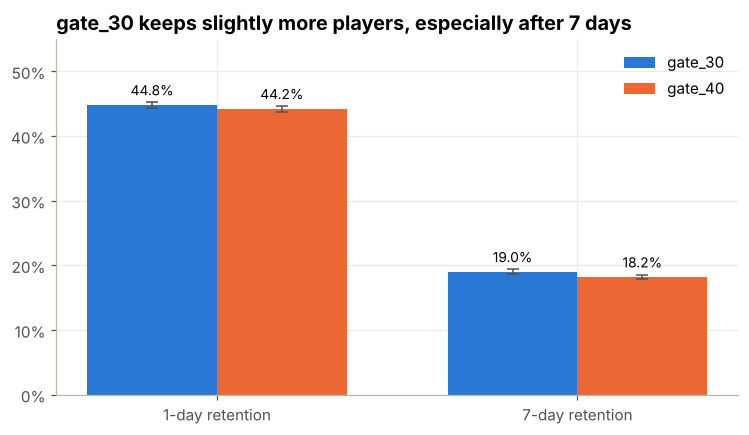

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(2); w = 0.36
for i, (v, c) in enumerate(COLORS.items()):
    rates = [summary.loc[v, "retention_1"], summary.loc[v, "retention_7"]]
    n = summary.loc[v, "players"]
    errs = [1.96 * np.sqrt(r / 100 * (1 - r / 100) / n) * 100 for r in rates]
    bars = ax.bar(x + (i - 0.5) * w, rates, w, yerr=errs, capsize=4, color=c, label=v,
                  error_kw={"ecolor": MUTED, "lw": 1})
    for b, r in zip(bars, rates):
        ax.text(b.get_x() + b.get_width() / 2, r + 1.5, f"{r:.1f}%", ha="center", fontsize=9)
ax.set_xticks(x, ["1-day retention", "7-day retention"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 55)
ax.set_title("gate_30 keeps slightly more players, especially after 7 days")
ax.legend(frameon=False)
plt.savefig(IMG / "02_retention_by_group.png"); plt.show()

## 4. Bootstrap: how confident are we?

The z-test relies on a formula. **Bootstrapping** checks the same thing by simulation, with no formula needed:
1. Draw a random sample of players **with replacement**, same size as the data
2. Calculate retention for each group in that sample
3. Repeat 1,000 times

This gives 1,000 possible values for each group's retention. If the two distributions barely overlap, the difference is real.

In [15]:
N_BOOT = 1000
boot = {"retention_1": [], "retention_7": []}
for _ in range(N_BOOT):
    sample = df.sample(frac=1, replace=True)
    means = sample.groupby("version")[["retention_1", "retention_7"]].mean()
    for m in boot:
        boot[m].append(means[m])

boot_1 = pd.DataFrame(boot["retention_1"]).reset_index(drop=True) * 100
boot_7 = pd.DataFrame(boot["retention_7"]).reset_index(drop=True) * 100
boot_7.head()

version,gate_30,gate_40
0,18.749023,18.010178
1,19.132013,18.214944
2,18.906738,18.394022
3,19.053694,18.198598
4,19.415286,18.355573


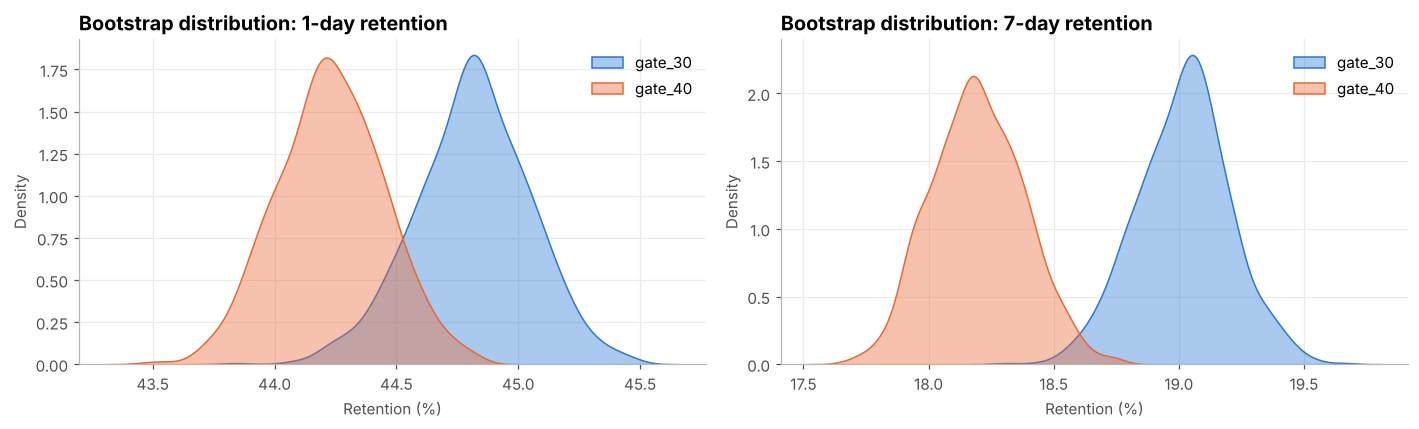

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, data, title in [(axes[0], boot_1, "1-day retention"), (axes[1], boot_7, "7-day retention")]:
    for v, c in COLORS.items():
        sns.kdeplot(data[v], fill=True, color=c, alpha=0.4, label=v, ax=ax)
    ax.set_title(f"Bootstrap distribution: {title}")
    ax.set_xlabel("Retention (%)"); ax.set_ylabel("Density")
    ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(IMG / "03_bootstrap_distributions.png"); plt.show()

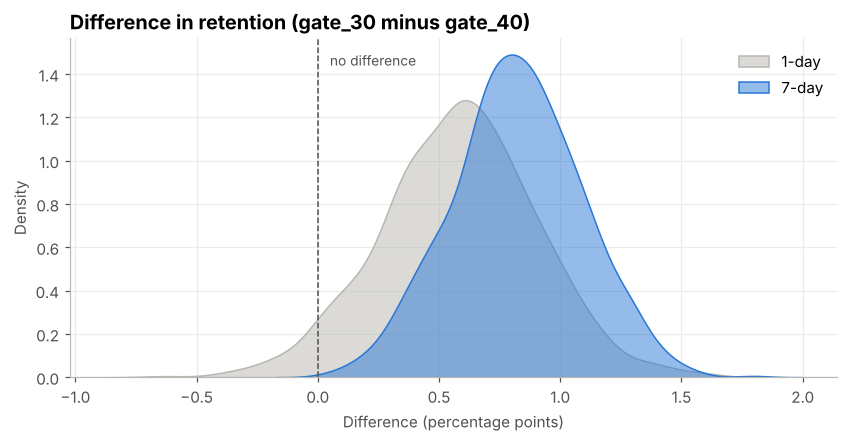

Probability that gate_30 has higher 1-day retention: 96.3%
Probability that gate_30 has higher 7-day retention: 100.0%
95% bootstrap interval for the 7-day difference: 0.30 to 1.33 percentage points


In [17]:
diff_1 = boot_1["gate_30"] - boot_1["gate_40"]
diff_7 = boot_7["gate_30"] - boot_7["gate_40"]
prob_1 = (diff_1 > 0).mean() * 100
prob_7 = (diff_7 > 0).mean() * 100

fig, ax = plt.subplots(figsize=(9, 4))
sns.kdeplot(diff_1, fill=True, color=GREY, alpha=0.5, label="1-day", ax=ax)
sns.kdeplot(diff_7, fill=True, color=BLUE, alpha=0.5, label="7-day", ax=ax)
ax.axvline(0, color=MUTED, lw=1, ls="--")
ax.text(0.05, ax.get_ylim()[1] * 0.92, "no difference", color=MUTED, fontsize=9)
ax.set_title("Difference in retention (gate_30 minus gate_40)")
ax.set_xlabel("Difference (percentage points)"); ax.set_ylabel("Density")
ax.legend(frameon=False)
plt.savefig(IMG / "04_bootstrap_difference.png"); plt.show()

print(f"Probability that gate_30 has higher 1-day retention: {prob_1:.1f}%")
print(f"Probability that gate_30 has higher 7-day retention: {prob_7:.1f}%")
print(f"95% bootstrap interval for the 7-day difference: "
      f"{diff_7.quantile(0.025):.2f} to {diff_7.quantile(0.975):.2f} percentage points")

## 5. Results and recommendation

In [18]:
r1, r7 = results.set_index("metric").loc["retention_1"], results.set_index("metric").loc["retention_7"]
print(f"1-day retention: gate_30 {r1['gate_30_%']:.2f}% vs gate_40 {r1['gate_40_%']:.2f}%  "
      f"(diff {r1['diff_pp']:.2f} pp, p = {r1['p_value']:.3f}) -> "
      f"{'significant' if r1['significant'] else 'NOT significant'}")
print(f"7-day retention: gate_30 {r7['gate_30_%']:.2f}% vs gate_40 {r7['gate_40_%']:.2f}%  "
      f"(diff {r7['diff_pp']:.2f} pp, p = {r7['p_value']:.4f}) -> "
      f"{'significant' if r7['significant'] else 'NOT significant'}")

# What the 7-day gap means at scale
per_million = r7["diff_pp"] / 100 * 1_000_000
print(f"\nFor every 1 million new installs, gate_40 would keep about {per_million:,.0f} fewer players at day 7.")

1-day retention: gate_30 44.82% vs gate_40 44.23%  (diff 0.59 pp, p = 0.074) -> NOT significant
7-day retention: gate_30 19.02% vs gate_40 18.20%  (diff 0.82 pp, p = 0.0016) -> significant

For every 1 million new installs, gate_40 would keep about 8,183 fewer players at day 7.


### Recommendation: **keep the gate at level 30**

- **7-day retention is significantly lower with gate_40** (about 0.8 percentage points, p ≈ 0.002). The bootstrap agrees: in all 1,000 resamples, gate_30 retained more players at day 7.
- **1-day retention:** the difference is small and **not significant** (p ≈ 0.07). gate_30 was higher in about 96% of bootstrap resamples, but that isn't strong enough to pass our 5% bar for a two-sided test. That's expected, since most players haven't reached level 30 or 40 after just one day.
- **Game rounds:** no significant difference (p ≈ 0.05, borderline).

**Why might an earlier gate help?** One explanation is that the gate forces a break. Players who stop at level 30 come back later still enjoying the game, while players who can binge to level 40 get bored sooner. This idea is known as *hedonic adaptation*.

**Business impact:** 7-day retention is a strong predictor of long-term players and revenue. Moving the gate would lose roughly 8,000 day-7 players per million installs, for no gain in engagement.

### Limitations
- The group split has a small but statistically significant imbalance (SRM, p ≈ 0.009). It should be checked with engineering before acting on the result.
- No revenue or in-app purchase data, so the impact on money is estimated through retention only.
- Retention is measured only up to day 7; longer-term effects are unknown.

### Next steps
- Investigate the SRM cause.
- If revenue data is available, test whether gate_40 changes purchases at the gate.
- Try a test with the gate at an *earlier* level (for example 20) to see whether retention improves further.

In [19]:
results.round(4).to_csv(OUT / "ab_test_results.csv", index=False)
summary.round(3).to_csv(OUT / "group_summary.csv")
print("Saved:", OUT / "ab_test_results.csv", "and", OUT / "group_summary.csv")

Saved: ../outputs/ab_test_results.csv and ../outputs/group_summary.csv
